In [1]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
#loading and normalizing MNIST Dataset to [0, 1]
transform = transforms.ToTensor()
train_dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset  = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=128, shuffle=False)

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 481kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.71MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.66MB/s]


In [4]:
#Defining Base Convolutional Autoencoder
class BaseAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        # Encoder: 28x28x1 -> 14x14x32 -> 7x7x64
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        # Decoder: 7x7x64 -> 14x14x32 -> 28x28x1
        self.decoder = nn.Sequential(
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Upsample(scale_factor=2, mode="nearest"),
            nn.Conv2d(64, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Upsample(scale_factor=2, mode="nearest"),
            nn.Conv2d(32, 1, kernel_size=3, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

In [5]:
# Reusable Training Helper (the input x is also the target x)
def train_autoencoder(model, epochs=15, lr=1e-3, name="Base Autoencoder"):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()  # Mean Squared Error measures pixel-by-pixel reconstruction error
    train_losses, val_losses = [], []

    for epoch in range(epochs):
        model.train()
        tr_loss = 0.0
        for imgs, _ in train_loader:
            imgs = imgs.to(device)
            optimizer.zero_grad()
            reconstructed = model(imgs)
            loss = criterion(reconstructed, imgs)
            loss.backward()
            optimizer.step()
            tr_loss += loss.item() * imgs.size(0)

        model.eval()
        v_loss = 0.0
        with torch.no_grad():
            for imgs, _ in test_loader:
                imgs = imgs.to(device)
                reconstructed = model(imgs)
                v_loss += criterion(reconstructed, imgs).item() * imgs.size(0)

        ep_tr = tr_loss / len(train_dataset)
        ep_val = v_loss / len(test_dataset)
        train_losses.append(ep_tr)
        val_losses.append(ep_val)
        print(f"[{name}] Epoch {epoch+1:02d}/{epochs} | Train MSE: {ep_tr:.5f} | Val MSE: {ep_val:.5f}")

    return model, train_losses, val_losses

base_ae, base_tr_loss, base_val_loss = train_autoencoder(BaseAutoencoder(), epochs=15, name="Base Autoencoder")

[Base Autoencoder] Epoch 01/15 | Train MSE: 0.11303 | Val MSE: 0.11396
[Base Autoencoder] Epoch 02/15 | Train MSE: 0.11200 | Val MSE: 0.11396
[Base Autoencoder] Epoch 03/15 | Train MSE: 0.11200 | Val MSE: 0.11396
[Base Autoencoder] Epoch 04/15 | Train MSE: 0.11200 | Val MSE: 0.11396
[Base Autoencoder] Epoch 05/15 | Train MSE: 0.11200 | Val MSE: 0.11396
[Base Autoencoder] Epoch 06/15 | Train MSE: 0.11200 | Val MSE: 0.11396
[Base Autoencoder] Epoch 07/15 | Train MSE: 0.11200 | Val MSE: 0.11396
[Base Autoencoder] Epoch 08/15 | Train MSE: 0.11200 | Val MSE: 0.11396
[Base Autoencoder] Epoch 09/15 | Train MSE: 0.11200 | Val MSE: 0.11396
[Base Autoencoder] Epoch 10/15 | Train MSE: 0.11200 | Val MSE: 0.11396
[Base Autoencoder] Epoch 11/15 | Train MSE: 0.11200 | Val MSE: 0.11396
[Base Autoencoder] Epoch 12/15 | Train MSE: 0.11200 | Val MSE: 0.11396
[Base Autoencoder] Epoch 13/15 | Train MSE: 0.11200 | Val MSE: 0.11396
[Base Autoencoder] Epoch 14/15 | Train MSE: 0.11200 | Val MSE: 0.11396
[Base 

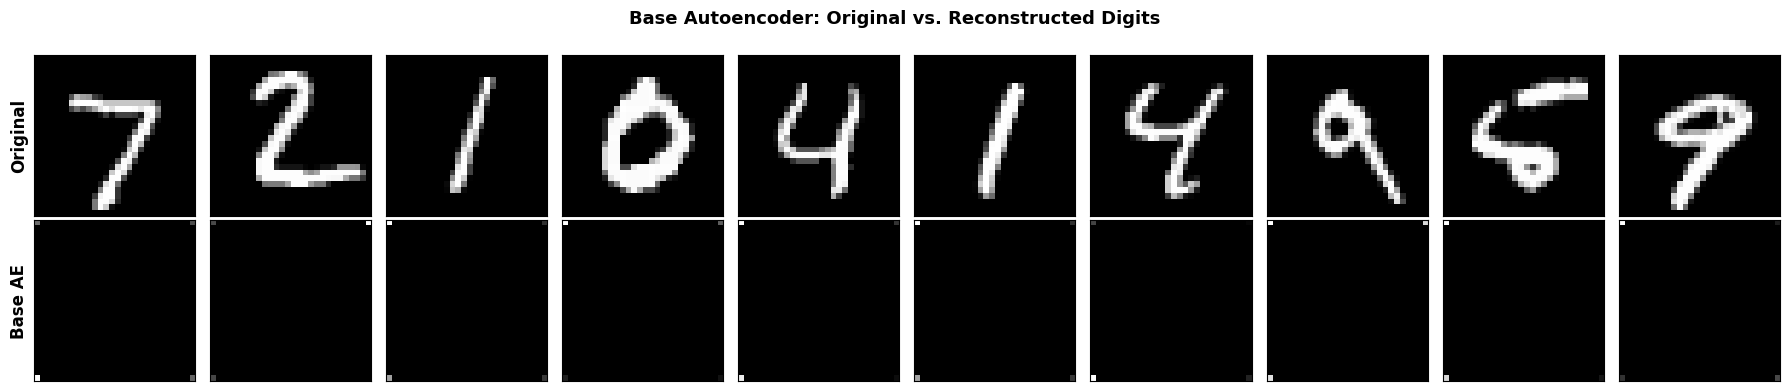

In [6]:
#visualizing original vs. base convolutional autoencoder reconstructed Digits
base_ae.eval()
test_imgs, _ = next(iter(test_loader))
with torch.no_grad():
    base_recon = base_ae(test_imgs[:10].to(device)).cpu()

plt.figure(figsize=(18, 4))
for i in range(10):
    ax = plt.subplot(2, 10, i + 1)
    plt.imshow(test_imgs[i, 0], cmap="gray")
    if i == 0: ax.set_ylabel("Original", fontsize=12, fontweight="bold")
    ax.set_xticks([]); ax.set_yticks([])

    ax = plt.subplot(2, 10, i + 11)
    plt.imshow(base_recon[i, 0], cmap="gray")
    if i == 0: ax.set_ylabel("Base AE", fontsize=12, fontweight="bold")
    ax.set_xticks([]); ax.set_yticks([])

plt.suptitle("Base Autoencoder: Original vs. Reconstructed Digits", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

The base autoencoder perfrmed poorly.
Gemini says: When the network starts with random weights, if the early updates push the pre-activation values negative, every ReLU layer outputs strict 0.0, killing all gradients completely: Dying ReLU problem. the improved autoencoder in the next cell accounts for this by replacing with LeakyReLU

In [7]:
#Solving for assigned task; improving the autoencoder
class ImprovedAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        #deeper Encoder with BatchNorm & LeakyReLU
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.LeakyReLU(0.2),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.LeakyReLU(0.2),
            nn.MaxPool2d(2, 2), # 28x28 -> 14x14

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2),
            nn.MaxPool2d(2, 2)  # 14x14 -> 7x7
        )
        # Decoder using Learned Transposed Convolutions (Deconvolutions)
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2), # 7x7 -> 14x14
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2),

            nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2),  # 14x14 -> 28x28
            nn.BatchNorm2d(32),
            nn.LeakyReLU(0.2),
            nn.Conv2d(32, 1, kernel_size=3, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))

imp_ae, imp_tr_loss, imp_val_loss = train_autoencoder(ImprovedAutoencoder(), epochs=15, name="Improved Autoencoder")

[Improved Autoencoder] Epoch 01/15 | Train MSE: 0.00590 | Val MSE: 0.00147
[Improved Autoencoder] Epoch 02/15 | Train MSE: 0.00106 | Val MSE: 0.00083
[Improved Autoencoder] Epoch 03/15 | Train MSE: 0.00078 | Val MSE: 0.00073
[Improved Autoencoder] Epoch 04/15 | Train MSE: 0.00067 | Val MSE: 0.00059
[Improved Autoencoder] Epoch 05/15 | Train MSE: 0.00058 | Val MSE: 0.00060
[Improved Autoencoder] Epoch 06/15 | Train MSE: 0.00051 | Val MSE: 0.00048
[Improved Autoencoder] Epoch 07/15 | Train MSE: 0.00049 | Val MSE: 0.00047
[Improved Autoencoder] Epoch 08/15 | Train MSE: 0.00044 | Val MSE: 0.00041
[Improved Autoencoder] Epoch 09/15 | Train MSE: 0.00041 | Val MSE: 0.00040
[Improved Autoencoder] Epoch 10/15 | Train MSE: 0.00039 | Val MSE: 0.00049
[Improved Autoencoder] Epoch 11/15 | Train MSE: 0.00036 | Val MSE: 0.00036
[Improved Autoencoder] Epoch 12/15 | Train MSE: 0.00033 | Val MSE: 0.00031
[Improved Autoencoder] Epoch 13/15 | Train MSE: 0.00032 | Val MSE: 0.00034
[Improved Autoencoder] Ep

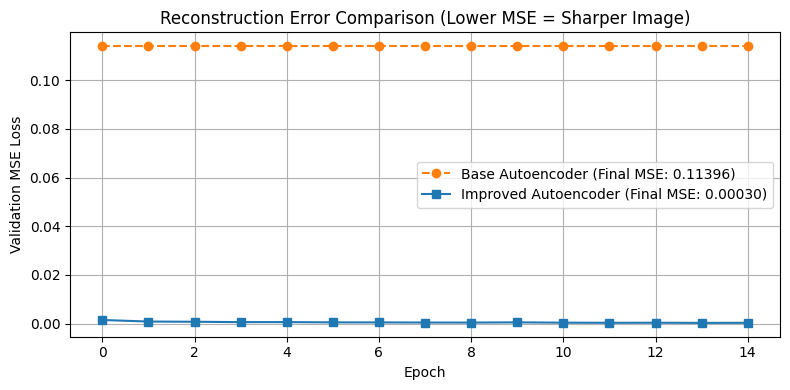

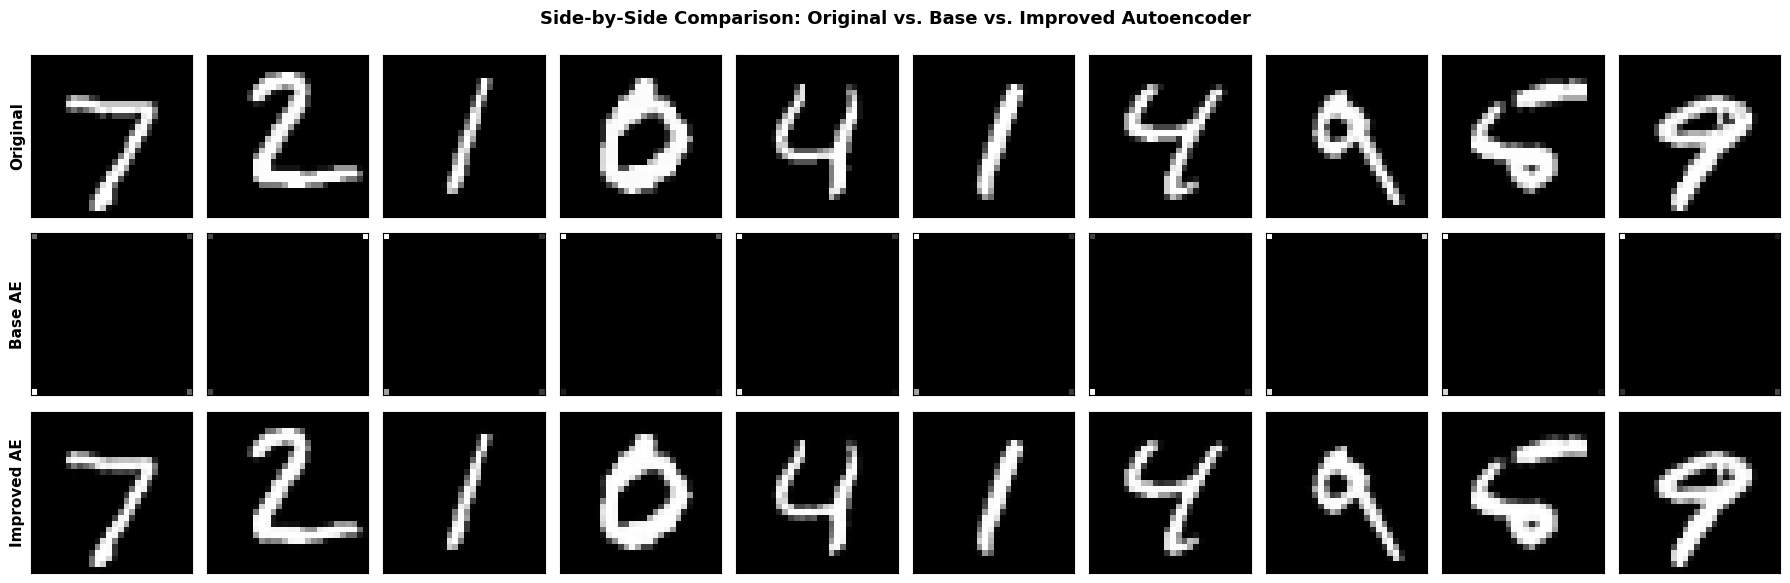

In [8]:
#comparative performance evaluation and visualization

#comparing reconstruction Error (MSE Loss) Curves
plt.figure(figsize=(8, 4))
plt.plot(base_val_loss, "--o", label=f"Base Autoencoder (Final MSE: {base_val_loss[-1]:.5f})", color="tab:orange")
plt.plot(imp_val_loss, "-s", label=f"Improved Autoencoder (Final MSE: {imp_val_loss[-1]:.5f})", color="tab:blue")
plt.title("Reconstruction Error Comparison (Lower MSE = Sharper Image)")
plt.xlabel("Epoch")
plt.ylabel("Validation MSE Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

#2. Original vs. Base Autoencoder vs. Improved Autoencoder (visualization)
imp_ae.eval()
with torch.no_grad():
    imp_recon = imp_ae(test_imgs[:10].to(device)).cpu()

plt.figure(figsize=(18, 6))
for i in range(10):
    # Row 1: Original
    ax = plt.subplot(3, 10, i + 1)
    plt.imshow(test_imgs[i, 0], cmap="gray")
    if i == 0: ax.set_ylabel("Original", fontsize=11, fontweight="bold")
    ax.set_xticks([]); ax.set_yticks([])

    # Row 2: Base Autoencoder
    ax = plt.subplot(3, 10, i + 11)
    plt.imshow(base_recon[i, 0], cmap="gray")
    if i == 0: ax.set_ylabel("Base AE", fontsize=11, fontweight="bold")
    ax.set_xticks([]); ax.set_yticks([])

    # Row 3: Improved Autoencoder
    ax = plt.subplot(3, 10, i + 21)
    plt.imshow(imp_recon[i, 0], cmap="gray")
    if i == 0: ax.set_ylabel("Improved AE", fontsize=11, fontweight="bold")
    ax.set_xticks([]); ax.set_yticks([])

plt.suptitle("Side-by-Side Comparison: Original vs. Base vs. Improved Autoencoder", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()